In [1]:
import os, sys, subprocess, json, random, shutil, time, platform, datetime, zipfile
from pathlib import Path

def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

try:
    import ultralytics
except ImportError:
    pip_install("ultralytics")
    import ultralytics

import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Image
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [2]:
# settings
SEED          = 42
CLASSES       = ["Cattle", "Goat", "Sheep"]
BASE_WEIGHTS  = "yolov8n.pt"            # same COCO-pretrained start as D2
EPOCHS, PATIENCE = 50, 10               # same as D2
BATCH_BASE, BATCH_HI = 16, 16           # lower BATCH_HI to 8 if the GPU runs out of memory
IMGSZ_BASE, IMGSZ_HI = 640, 960         # D2 used 640; D3 tries 960
IOU_NMS       = 0.7                     # NMS IoU used by D2
CONF_REF      = 0.25                    # D2 headline counting threshold
CACHE_CONF    = 0.005                   # predictions are cached down to this confidence, then filtered
THR_GRID      = np.round(np.arange(0.10, 0.61, 0.05), 2)   # thresholds tried on the VALIDATION split
TILE_GRID     = [512, 384]              # tile sizes (pixels of the original photo) tried on validation
MERGE_IOU_GRID = [0.5, 0.6]             # overlap limit used when merging tile results
TILE_OVERLAP  = 0.25
RETRAIN       = True                    # False = reuse weights from an earlier run in this session
REUSE_960     = True                    # True = if an earlier D3 run is attached, reuse its 960 px weights instead of training again
TILE_MAX_AREA_GRID = [0.01, 0.03]       # variant E: tiles may only add boxes up to this share of the photo area
GATE_K_GRID   = [3, 5, 8]               # variant F: tiles are used only if the whole photo already has at least K animals
N_BOOT_MAE    = 2000                    # bootstrap resamples for counting differences
N_BOOT_AP     = 200                     # bootstrap resamples for mAP differences (slower)

WORK    = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd() / "working"
RAW_DIR = WORK / "livestock_raw"
DATA_DIR = WORK / "livestock_dataset"
RUNS_DIR = WORK / "runs"
OUT_DIR = WORK / "outputs"
FIG_DIR, TAB_DIR, PRED_DIR = OUT_DIR / "figures", OUT_DIR / "tables", OUT_DIR / "sample_predictions"
for d in (FIG_DIR, TAB_DIR, PRED_DIR, RUNS_DIR):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (training will be very slow)")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed(SEED)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASS_COLORS = ["#2ca02c", "#ff7f0e", "#1f77b4"]
BOX_BGR = [(44, 160, 44), (14, 127, 255), (180, 119, 31)]
RESULTS = {}

Device: Tesla T4


In [3]:
PIPELINE_SRC = '''# pipeline.py : inference code for the livestock counter (tiled + whole-image detection)
import numpy as np

CLASS_NAMES = ["Cattle", "Goat", "Sheep"]


def nms_np(boxes, scores, iou_thr):
    if len(boxes) == 0:
        return np.array([], dtype=int)
    x1, y1, x2, y2 = boxes.T
    areas = (x2 - x1).clip(0) * (y2 - y1).clip(0)
    order = scores.argsort()[::-1]
    keep = []
    while order.size:
        i = order[0]
        keep.append(i)
        if order.size == 1:
            break
        rest = order[1:]
        xx1 = np.maximum(x1[i], x1[rest]); yy1 = np.maximum(y1[i], y1[rest])
        xx2 = np.minimum(x2[i], x2[rest]); yy2 = np.minimum(y2[i], y2[rest])
        inter = (xx2 - xx1).clip(0) * (yy2 - yy1).clip(0)
        iou = inter / (areas[i] + areas[rest] - inter + 1e-9)
        order = rest[iou <= iou_thr]
    return np.array(keep, dtype=int)


def classwise_nms(boxes, scores, classes, iou_thr):
    keep = []
    for c in np.unique(classes):
        idx = np.where(classes == c)[0]
        k = nms_np(boxes[idx], scores[idx], iou_thr)
        keep.extend(idx[k].tolist())
    return np.array(sorted(keep), dtype=int)


def tile_starts(length, tile, overlap):
    if length <= tile:
        return [0]
    step = max(1, int(tile * (1 - overlap)))
    starts = list(range(0, length - tile + 1, step))
    if starts[-1] != length - tile:
        starts.append(length - tile)
    return starts


def _to_pred(r):
    return dict(conf=r.boxes.conf.cpu().numpy(),
                cls=r.boxes.cls.cpu().numpy().astype(int),
                xyxyn=r.boxes.xyxyn.cpu().numpy())


def predict_full_batch(model, paths, imgsz, conf=0.005, iou=0.7, device=None, chunk=32):
    out = {}
    for i in range(0, len(paths), chunk):
        part = [str(p) for p in paths[i:i + chunk]]
        res = model.predict(part, imgsz=imgsz, conf=conf, iou=iou, device=device, verbose=False, max_det=1000)
        for p, r in zip(part, res):
            out[p.replace("\\\\", "/").split("/")[-1]] = _to_pred(r)
    return out


def predict_tiled(model, img_bgr, imgsz, tile=512, overlap=0.25, conf=0.005, iou=0.7, merge_iou=0.55,
                  device=None, edge_drop=True, edge_margin=3, include_full=True, chunk=16, tile_max_area=None,
                  gate_k=None, gate_conf=0.3):
    H, W = img_bgr.shape[:2]
    boxes, scores, classes = [], [], []
    skip_tiles = False
    if include_full:
        r = model.predict(img_bgr, imgsz=imgsz, conf=conf, iou=iou, device=device, verbose=False, max_det=1000)[0]
        full_conf = r.boxes.conf.cpu().numpy()
        boxes.append(r.boxes.xyxy.cpu().numpy()); scores.append(full_conf)
        classes.append(r.boxes.cls.cpu().numpy().astype(int))
        skip_tiles = gate_k is not None and int((full_conf >= gate_conf).sum()) < gate_k
    crops, origins = [], []
    if not skip_tiles:
        for y0 in tile_starts(H, tile, overlap):
            for x0 in tile_starts(W, tile, overlap):
                crops.append(img_bgr[y0:y0 + tile, x0:x0 + tile]); origins.append((x0, y0))
    for i in range(0, len(crops), chunk):
        res = model.predict(crops[i:i + chunk], imgsz=imgsz, conf=conf, iou=iou, device=device, verbose=False, max_det=1000)
        for r, (x0, y0), crop in zip(res, origins[i:i + chunk], crops[i:i + chunk]):
            b = r.boxes.xyxy.cpu().numpy().copy()
            if len(b) == 0:
                continue
            th, tw = crop.shape[:2]
            b[:, [0, 2]] += x0; b[:, [1, 3]] += y0
            ok = np.ones(len(b), dtype=bool)
            if edge_drop:
                if x0 > 0:           ok &= b[:, 0] > x0 + edge_margin
                if x0 + tw < W:      ok &= b[:, 2] < x0 + tw - edge_margin
                if y0 > 0:           ok &= b[:, 1] > y0 + edge_margin
                if y0 + th < H:      ok &= b[:, 3] < y0 + th - edge_margin
            if tile_max_area is not None:
                ok &= ((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])) <= tile_max_area * H * W
            boxes.append(b[ok]); scores.append(r.boxes.conf.cpu().numpy()[ok])
            classes.append(r.boxes.cls.cpu().numpy().astype(int)[ok])
    if not boxes or sum(len(b) for b in boxes) == 0:
        return dict(conf=np.zeros(0), cls=np.zeros(0, dtype=int), xyxyn=np.zeros((0, 4)))
    boxes = np.concatenate(boxes); scores = np.concatenate(scores); classes = np.concatenate(classes)
    keep = classwise_nms(boxes, scores, classes, merge_iou)
    boxes, scores, classes = boxes[keep], scores[keep], classes[keep]
    return dict(conf=scores, cls=classes, xyxyn=boxes / np.array([W, H, W, H], dtype=float))


def run_pipeline(model, img_bgr, cfg):
    # cfg keys: imgsz, conf, iou, tile (None for whole image only), overlap, merge_iou, tile_max_area, gate_k, gate_conf, device
    if cfg.get("tile"):
        p = predict_tiled(model, img_bgr, cfg["imgsz"], tile=cfg["tile"], overlap=cfg.get("overlap", 0.25),
                          conf=min(cfg["conf"], 0.05), iou=cfg.get("iou", 0.7), merge_iou=cfg.get("merge_iou", 0.55),
                          device=cfg.get("device"), tile_max_area=cfg.get("tile_max_area"),
                          gate_k=cfg.get("gate_k"), gate_conf=cfg.get("gate_conf", 0.3))
    else:
        r = model.predict(img_bgr, imgsz=cfg["imgsz"], conf=min(cfg["conf"], 0.05), iou=cfg.get("iou", 0.7),
                          device=cfg.get("device"), verbose=False, max_det=1000)[0]
        p = _to_pred(r)
    keep = p["conf"] >= cfg["conf"]
    p = dict(conf=p["conf"][keep], cls=p["cls"][keep], xyxyn=p["xyxyn"][keep])
    counts = {n: int((p["cls"] == i).sum()) for i, n in enumerate(CLASS_NAMES)}
    return p, counts
'''
exec(PIPELINE_SRC)
(OUT_DIR / "pipeline.py").write_text(PIPELINE_SRC)
print("pipeline.py written; functions loaded.")

pipeline.py written; functions loaded.


In [4]:
def find_dir_with(files, bases):
    for b in bases:
        if not Path(b).exists():
            continue
        for root, dirs, fs in os.walk(b):
            if all(f in fs for f in files):
                return Path(root)
    return None

def find_file(name, bases, parent_name=None):
    for b in bases:
        if not Path(b).exists():
            continue
        for root, dirs, fs in os.walk(b):
            if name in fs and (parent_name is None or Path(root).name == parent_name) and "/runs/" not in root.replace("\\", "/"):
                return Path(root) / name
    return None

SEARCH = ["/kaggle/input", str(Path.cwd())]
SPLITS_DIR = find_dir_with(["train.txt", "val.txt", "test.txt"], SEARCH)
BASE_BEST  = find_file("best.pt", SEARCH, parent_name="weights") or find_file("best.pt", SEARCH)
assert SPLITS_DIR is not None, "Could not find the D2 splits/ folder. Attach your D2 package as a Kaggle Dataset (see the top of the notebook)."
assert BASE_BEST is not None, "Could not find the D2 weights (best.pt). Attach your D2 package as a Kaggle Dataset."
print("D2 split lists :", SPLITS_DIR)
print("D2 weights     :", BASE_BEST)

split_names = {s: [l.strip() for l in (SPLITS_DIR / f"{s}.txt").read_text().splitlines() if l.strip()] for s in ("train", "val", "test")}
print({s: len(v) for s, v in split_names.items()})
sets = {s: set(v) for s, v in split_names.items()}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not (sets[a] & sets[b]), f"Overlap between {a} and {b}"
print("No photo appears in more than one split.")

D2 split lists : /kaggle/input/notebooks/amanyaedwin/deliverable-3/outputs/splits
D2 weights     : /kaggle/input/notebooks/amanyaedwin/deliverable-2/outputs/weights/best.pt
{'train': 1050, 'val': 225, 'test': 225}
No photo appears in more than one split.


In [5]:
def list_images(folder):
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in IMG_EXT)

def parse_label_file(path):
    # returns (valid boxes as (cls, xc, yc, w, h), number of invalid lines)
    boxes, bad, tol = [], 0, 1e-6
    path = Path(path)
    if not path.exists():
        return boxes, 0
    for line in path.read_text().splitlines():
        p = line.split()
        if not p:
            continue
        try:
            assert len(p) == 5
            c = int(float(p[0])); xc, yc, w, h = map(float, p[1:])
            assert 0 <= c < len(CLASSES)
            assert -tol <= xc <= 1 + tol and -tol <= yc <= 1 + tol and 0 < w <= 1 + tol and 0 < h <= 1 + tol
            boxes.append((c, xc, yc, w, h))
        except Exception:
            bad += 1
    return boxes, bad

def rgb(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

In [6]:
EXPECTED = dict(train=(1050, 3788), val=(225, 819), test=(225, 830))     # images, boxes reported in D2

def find_yolo_root(base):
    for root, dirs, _ in os.walk(base):
        if "images" in dirs and "labels" in dirs and (Path(root) / "images" / "test").exists():
            return Path(root)
    return None

ready = DATA_DIR.exists() and all(len(list_images(DATA_DIR / "images" / s)) == len(split_names[s]) for s in split_names)
if ready:
    print("Dataset already rebuilt in", DATA_DIR)
    DATASET_SOURCE = "rebuilt earlier in this session"
else:
    attached = find_yolo_root("/kaggle/input") if Path("/kaggle/input").exists() else None
    if attached is not None:
        print("Using prepared dataset attached to this notebook:", attached)
        DATASET_SOURCE = f"attached dataset {attached}"
        SRC_IMG_ROOT, SRC_LBL_ROOT = attached / "images", attached / "labels"
    else:
        print("Downloading the 1,500 D2 photos from Open Images V7 by image ID (Internet must be On)...")
        DATASET_SOURCE = "downloaded from Open Images V7 by image ID"
        pip_install("fiftyone")
        import fiftyone as fo, fiftyone.zoo as foz
        ids = [Path(n).stem for s in split_names.values() for n in s]
        ds = foz.load_zoo_dataset("open-images-v7", split="train", label_types=["detections"], classes=CLASSES, image_ids=ids)
        if RAW_DIR.exists():
            shutil.rmtree(RAW_DIR)
        ds.export(export_dir=str(RAW_DIR), dataset_type=fo.types.YOLOv5Dataset, label_field="ground_truth", classes=CLASSES, split="train")
        SRC_IMG_ROOT, SRC_LBL_ROOT = RAW_DIR / "images", RAW_DIR / "labels"
    src_imgs = {p.name: p for p in list_images(SRC_IMG_ROOT)}
    if DATA_DIR.exists():
        shutil.rmtree(DATA_DIR)
    missing = []
    for s, names in split_names.items():
        (DATA_DIR / "images" / s).mkdir(parents=True); (DATA_DIR / "labels" / s).mkdir(parents=True)
        for n in names:
            if n not in src_imgs:
                missing.append(n); continue
            p = src_imgs[n]
            rel = p.relative_to(SRC_IMG_ROOT)
            boxes, _ = parse_label_file((SRC_LBL_ROOT / rel).with_suffix(".txt"))
            shutil.copy2(p, DATA_DIR / "images" / s / n)
            lines = [f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}" for c, x, y, w, h in boxes]
            (DATA_DIR / "labels" / s / (Path(n).stem + ".txt")).write_text("\n".join(lines) + "\n")
    print("Photos not found:", len(missing))
    assert not missing, "Some D2 photos could not be recovered; see the list: " + ", ".join(missing[:5])

DATA_YAML = DATA_DIR / "data.yaml"
DATA_YAML.write_text(f"path: {DATA_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n" + "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES)))

# --- check against the D2 numbers ---
rows = []
for s in split_names:
    imgs = list_images(DATA_DIR / "images" / s)
    nb = sum(len(parse_label_file(DATA_DIR / "labels" / s / (f.stem + ".txt"))[0]) for f in imgs)
    rows.append(dict(split=s, images=len(imgs), boxes=nb, D2_images=EXPECTED[s][0], D2_boxes=EXPECTED[s][1],
                     same=(len(imgs), nb) == EXPECTED[s]))
chk = pd.DataFrame(rows); display(chk)
if not chk.same.all():
    print("WARNING: the box counts differ from D2. The photos are the same, but the labels returned by the download differ. "
          "Report this honestly, and compare variants A-D only with each other (all use this data).")

Using prepared dataset attached to this notebook: /kaggle/input/notebooks/amanyaedwin/deliverable-3/livestock_dataset
Photos not found: 0


,split,images,boxes,D2_images,D2_boxes,same
0,train,1050,3788,1050,3788,True
1,val,225,819,225,819,True
2,test,225,830,225,830,True


In [7]:
def iou_one_to_many(b, bs):
    x1 = np.maximum(b[0], bs[:, 0]); y1 = np.maximum(b[1], bs[:, 1]); x2 = np.minimum(b[2], bs[:, 2]); y2 = np.minimum(b[3], bs[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    return inter / ((b[2] - b[0]) * (b[3] - b[1]) + (bs[:, 2] - bs[:, 0]) * (bs[:, 3] - bs[:, 1]) - inter + 1e-9)

def load_gt(split):
    gt = {}
    for f in list_images(DATA_DIR / "images" / split):
        boxes, _ = parse_label_file(DATA_DIR / "labels" / split / (f.stem + ".txt"))
        if boxes:
            a = np.array(boxes, dtype=float)
            xyxy = np.stack([a[:, 1] - a[:, 3] / 2, a[:, 2] - a[:, 4] / 2, a[:, 1] + a[:, 3] / 2, a[:, 2] + a[:, 4] / 2], axis=1)
            gt[f.name] = (a[:, 0].astype(int), xyxy, a[:, 3] * a[:, 4])
        else:
            gt[f.name] = (np.zeros(0, dtype=int), np.zeros((0, 4)), np.zeros(0))
    return gt

def match_dets(preds, gt, thr, iou_thr=0.5):
    # greedy class-aware matching of detections with conf >= thr to ground truth boxes
    tp = fp = fn = 0
    recs = []
    for n, (gc, gb, ga) in gt.items():
        p = preds[n]; keep = p["conf"] >= thr
        pc, pb, ps = p["cls"][keep], p["xyxyn"][keep], p["conf"][keep]
        used = np.zeros(len(gc), dtype=bool); hit = np.zeros(len(gc), dtype=bool)
        for j in np.argsort(-ps):
            cand = np.where((gc == pc[j]) & ~used)[0]
            if len(cand) == 0:
                fp += 1; continue
            ious = iou_one_to_many(pb[j], gb[cand]); k = int(ious.argmax())
            if ious[k] >= iou_thr:
                used[cand[k]] = True; hit[cand[k]] = True; tp += 1
            else:
                fp += 1
        fn += int((~hit).sum())
        recs += [dict(cls=int(gc[i]), area=float(ga[i]), hit=bool(hit[i])) for i in range(len(gc))]
    return tp, fp, fn, pd.DataFrame(recs)

def ap50_per_class(preds, gt, iou_thr=0.5):
    trap = getattr(np, "trapezoid", None) or getattr(np, "trapz")
    out = []
    for c in range(len(CLASSES)):
        n_gt = int(sum((g[0] == c).sum() for g in gt.values()))
        dets = []
        for n, p in preds.items():
            m = p["cls"] == c
            dets += [(cf, n, bx) for cf, bx in zip(p["conf"][m], p["xyxyn"][m])]
        dets.sort(key=lambda d: -d[0])
        used = {n: np.zeros(len(g[0]), dtype=bool) for n, g in gt.items()}
        tp = np.zeros(len(dets)); fp = np.zeros(len(dets))
        for i, (cf, n, bx) in enumerate(dets):
            gc, gb, _ = gt[n]
            cand = np.where((gc == c) & ~used[n])[0]
            if len(cand):
                ious = iou_one_to_many(bx, gb[cand]); k = int(ious.argmax())
                if ious[k] >= iou_thr:
                    used[n][cand[k]] = True; tp[i] = 1; continue
            fp[i] = 1
        ctp, cfp = np.cumsum(tp), np.cumsum(fp)
        rec = ctp / max(n_gt, 1); prec = ctp / np.maximum(ctp + cfp, 1e-9)
        mrec = np.concatenate([[0.0], rec, [1.0]]); mpre = np.concatenate([[1.0], prec, [0.0]])
        mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
        x = np.linspace(0, 1, 101)
        out.append(float(trap(np.interp(x, mrec, mpre), x)))
    return out

HERD_BINS, HERD_LABELS = [0, 2, 5, 10, 10 ** 6], ["1 to 2", "3 to 5", "6 to 10", "more than 10"]

def count_df(preds, gt, thr):
    rows = []
    for n, (gc, _, _) in gt.items():
        p = preds[n]; keep = p["conf"] >= thr
        row = dict(image=n, gt_total=len(gc), pred_total=int(keep.sum()))
        for i, c in enumerate(CLASSES):
            row[f"gt_{c}"] = int((gc == i).sum()); row[f"pred_{c}"] = int(((p["cls"] == i) & keep).sum())
        rows.append(row)
    df = pd.DataFrame(rows)
    df["error"] = df.pred_total - df.gt_total
    df["abs_error"] = df.error.abs()
    df["herd"] = pd.cut(df.gt_total, HERD_BINS, labels=HERD_LABELS)
    return df

def count_summary(df):
    e = df.error
    return dict(MAE=float(e.abs().mean()), RMSE=float(np.sqrt((e ** 2).mean())), Bias=float(e.mean()),
                Exact_pct=float(100 * (e == 0).mean()), Within1_pct=float(100 * (e.abs() <= 1).mean()))

def best_threshold(preds_val, gt_val):
    maes = {float(t): count_df(preds_val, gt_val, t).abs_error.mean() for t in THR_GRID}
    t = min(maes, key=maes.get)
    return t, maes[t]

SIZE_BINS, SIZE_LABELS = [0, 0.01, 0.10, 1.01], ["small (<1%)", "medium (1-10%)", "large (>10%)"]
GT = {"val": load_gt("val"), "test": load_gt("test")}
print("Ground truth loaded:", {s: (len(g), int(sum(len(v[0]) for v in g.values()))) for s, g in GT.items()})

Ground truth loaded: {'val': (225, 819), 'test': (225, 830)}


In [8]:
VARIANTS = {}      # name -> dict(model, weights, imgsz, tiling)
P = {}             # (name, split) -> cached predictions

def predict_variant(var, split, desc=""):
    files = list_images(DATA_DIR / "images" / split)
    if var["tiling"] is None:
        return predict_full_batch(var["model"], files, var["imgsz"], conf=CACHE_CONF, iou=IOU_NMS, device=DEVICE)
    t, out = var["tiling"], {}
    for f in tqdm(files, desc=desc or f"tiled {split}"):
        out[f.name] = predict_tiled(var["model"], cv2.imread(str(f)), var["imgsz"], tile=t["tile"], overlap=TILE_OVERLAP,
                                    conf=CACHE_CONF, iou=IOU_NMS, merge_iou=t["merge_iou"], device=DEVICE,
                                    tile_max_area=t.get("max_area"), gate_k=t.get("gate_k"),
                                    gate_conf=t.get("gate_conf", 0.3))
    return out

NAME_A = "A. Baseline (640 px)"
VARIANTS[NAME_A] = dict(model=YOLO(str(BASE_BEST)), weights=BASE_BEST, imgsz=IMGSZ_BASE, tiling=None)
for s in ("val", "test"):
    P[(NAME_A, s)] = predict_variant(VARIANTS[NAME_A], s)

tpA, fpA, fnA, _ = match_dets(P[(NAME_A, "test")], GT["test"], CONF_REF)
dA = count_df(P[(NAME_A, "test")], GT["test"], CONF_REF)
print(f"Reproduction check (test, threshold {CONF_REF}):")
print(f"  precision = {tpA / max(tpA + fpA, 1):.3f} (D2: 0.611) | recall = {tpA / max(tpA + fnA, 1):.3f} (D2: 0.566) | "
      f"AP50 mean = {np.mean(ap50_per_class(P[(NAME_A, 'test')], GT['test'])):.3f} (D2: 0.586) | counting MAE = {dA.abs_error.mean():.2f} (D2: 1.35)")

Reproduction check (test, threshold 0.25):
  precision = 0.586 (D2: 0.611) | recall = 0.593 (D2: 0.566) | AP50 mean = 0.560 (D2: 0.586) | counting MAE = 1.35 (D2: 1.35)


In [9]:
def choose_tiling(model, imgsz, label, max_areas=(None,)):
    rows, best, best_pred = [], None, None
    for tile in TILE_GRID:
        for miou in MERGE_IOU_GRID:
            for ma in max_areas:
                var = dict(model=model, imgsz=imgsz, tiling=dict(tile=tile, merge_iou=miou, max_area=ma))
                pv = predict_variant(var, "val", desc=f"{label} val tile={tile} merge={miou} maxarea={ma}")
                thr, mae = best_threshold(pv, GT["val"])
                rows.append(dict(tile=tile, merge_iou=miou, max_area=(-1.0 if ma is None else ma), best_thr=thr, val_MAE=mae,
                                 val_AP50=float(np.mean(ap50_per_class(pv, GT["val"])))))
                if best is None or mae < best["val_MAE"]:
                    best, best_pred = rows[-1], pv
    grid = pd.DataFrame(rows); display(grid.round(3))
    ma_best = None if best["max_area"] < 0 else float(best["max_area"])
    return dict(tile=int(best["tile"]), merge_iou=float(best["merge_iou"]), max_area=ma_best), best_pred, grid

tilingB, pvB, gridB = choose_tiling(VARIANTS[NAME_A]["model"], IMGSZ_BASE, "B")
gridB.to_csv(TAB_DIR / "tiling_grid_baseline_weights_val.csv", index=False)
NAME_B = "B. Baseline + tiling"
VARIANTS[NAME_B] = dict(model=VARIANTS[NAME_A]["model"], weights=BASE_BEST, imgsz=IMGSZ_BASE, tiling=tilingB)
P[(NAME_B, "val")] = pvB
P[(NAME_B, "test")] = predict_variant(VARIANTS[NAME_B], "test", desc="B test")
print("Chosen tiling for B (validation):", tilingB)

B val tile=512 merge=0.5 maxarea=None:   0%|          | 0/225 [00:00<?, ?it/s]

B val tile=512 merge=0.6 maxarea=None:   0%|          | 0/225 [00:00<?, ?it/s]

B val tile=384 merge=0.5 maxarea=None:   0%|          | 0/225 [00:00<?, ?it/s]

B val tile=384 merge=0.6 maxarea=None:   0%|          | 0/225 [00:00<?, ?it/s]

,tile,merge_iou,max_area,best_thr,val_MAE,val_AP50
0,512,0.5,-1.0,0.4,1.613,0.572
1,512,0.6,-1.0,0.5,1.613,0.568
2,384,0.5,-1.0,0.5,1.551,0.569
3,384,0.6,-1.0,0.5,1.547,0.566


B test:   0%|          | 0/225 [00:00<?, ?it/s]

Chosen tiling for B (validation): {'tile': 384, 'merge_iou': 0.6, 'max_area': None}


Reusing the 960 px weights from the earlier D3 run (not training again): /kaggle/input/notebooks/amanyaedwin/deliverable-3/runs/d3_yolov8n_960/weights/best.pt
Best 960 px weights: /kaggle/input/notebooks/amanyaedwin/deliverable-3/runs/d3_yolov8n_960/weights/best.pt


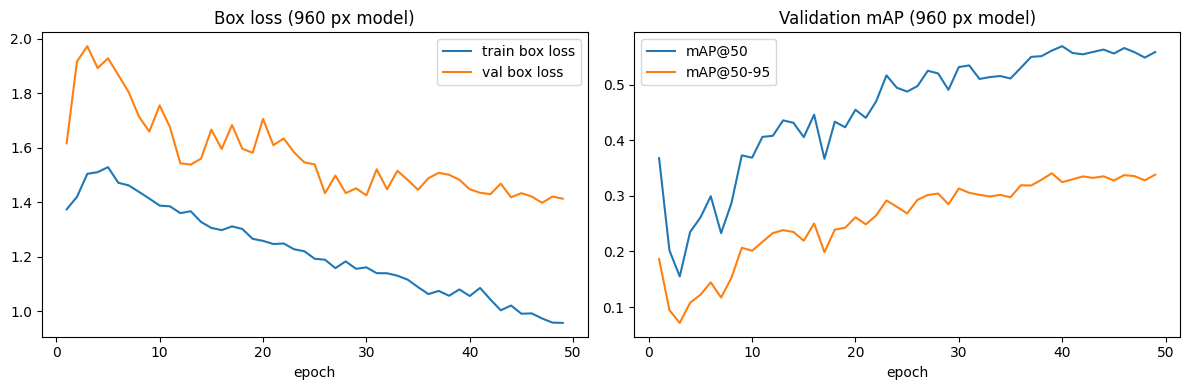

Epochs run: 49 | best epoch: 39


In [10]:
RUN_HI = "d3_yolov8n_960"
BEST_HI = RUNS_DIR / RUN_HI / "weights" / "best.pt"
train_minutes = None

def find_prev_960():
    for root, dirs, fs in os.walk("/kaggle/input") if Path("/kaggle/input").exists() else []:
        if "best.pt" in fs and root.replace("\\", "/").endswith("d3_yolov8n_960/weights"):
            return Path(root) / "best.pt"
    return None

PREV_960 = find_prev_960() if REUSE_960 else None
if PREV_960 is not None:
    BEST_HI = PREV_960
    print("Reusing the 960 px weights from the earlier D3 run (not training again):", BEST_HI)
elif RETRAIN or not BEST_HI.exists():
    set_seed(SEED)
    t0 = time.time()
    m = YOLO(BASE_WEIGHTS)
    m.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ_HI, batch=BATCH_HI, patience=PATIENCE, seed=SEED,
            project=str(RUNS_DIR), name=RUN_HI, exist_ok=True, device=DEVICE, workers=2, plots=True)
    train_minutes = round((time.time() - t0) / 60, 1)
    BEST_HI = Path(m.trainer.best)
    print(f"Training took {train_minutes} minutes.")
else:
    print("Reusing existing weights:", BEST_HI)
print("Best 960 px weights:", BEST_HI)

csv = BEST_HI.parent.parent / "results.csv"
if csv.exists():
    hist = pd.read_csv(csv); hist.columns = hist.columns.str.strip()
    hist.to_csv(TAB_DIR / "training_history_960.csv", index=False)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist["epoch"], hist["train/box_loss"], label="train box loss"); ax[0].plot(hist["epoch"], hist["val/box_loss"], label="val box loss")
    ax[0].set_title("Box loss (960 px model)"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["epoch"], hist["metrics/mAP50(B)"], label="mAP@50"); ax[1].plot(hist["epoch"], hist["metrics/mAP50-95(B)"], label="mAP@50-95")
    ax[1].set_title("Validation mAP (960 px model)"); ax[1].set_xlabel("epoch"); ax[1].legend()
    savefig("fig_D3_training_curves_960.png")
    print("Epochs run:", len(hist), "| best epoch:", int(hist.loc[hist["metrics/mAP50-95(B)"].idxmax(), "epoch"]))

## 7. Variants C and D: the 960 px model, whole photo and tiled

In [11]:
model_hi = YOLO(str(BEST_HI))
NAME_C = "C. Higher resolution (960 px)"
VARIANTS[NAME_C] = dict(model=model_hi, weights=BEST_HI, imgsz=IMGSZ_HI, tiling=None)
for s in ("val", "test"):
    P[(NAME_C, s)] = predict_variant(VARIANTS[NAME_C], s)

tilingD, pvD, gridD = choose_tiling(model_hi, IMGSZ_HI, "D")
gridD.to_csv(TAB_DIR / "tiling_grid_960_val.csv", index=False)
NAME_D = "D. Higher resolution + tiling"
VARIANTS[NAME_D] = dict(model=model_hi, weights=BEST_HI, imgsz=IMGSZ_HI, tiling=tilingD)
P[(NAME_D, "val")] = pvD
P[(NAME_D, "test")] = predict_variant(VARIANTS[NAME_D], "test", desc="D test")
print("Chosen tiling for D (validation):", tilingD)

D val tile=512 merge=0.5 maxarea=None:   0%|          | 0/225 [00:00<?, ?it/s]

D val tile=512 merge=0.6 maxarea=None:   0%|          | 0/225 [00:00<?, ?it/s]

D val tile=384 merge=0.5 maxarea=None:   0%|          | 0/225 [00:00<?, ?it/s]

D val tile=384 merge=0.6 maxarea=None:   0%|          | 0/225 [00:00<?, ?it/s]

,tile,merge_iou,max_area,best_thr,val_MAE,val_AP50
0,512,0.5,-1.0,0.50,1.636,0.546
1,512,0.6,-1.0,0.55,1.662,0.547
2,384,0.5,-1.0,0.45,1.684,0.547
3,384,0.6,-1.0,0.45,1.720,0.546


D test:   0%|          | 0/225 [00:00<?, ?it/s]

Chosen tiling for D (validation): {'tile': 512, 'merge_iou': 0.5, 'max_area': None}


In [12]:
tilingE, pvE, gridE = choose_tiling(VARIANTS[NAME_A]["model"], IMGSZ_BASE, "E", max_areas=TILE_MAX_AREA_GRID)
gridE.to_csv(TAB_DIR / "tiling_grid_size_aware_val.csv", index=False)
NAME_E = "E. Baseline + size-aware tiling"
VARIANTS[NAME_E] = dict(model=VARIANTS[NAME_A]["model"], weights=BASE_BEST, imgsz=IMGSZ_BASE, tiling=tilingE)
P[(NAME_E, "val")] = pvE
P[(NAME_E, "test")] = predict_variant(VARIANTS[NAME_E], "test", desc="E test")
print("Chosen setting for E (validation):", tilingE)

E val tile=512 merge=0.5 maxarea=0.01:   0%|          | 0/225 [00:00<?, ?it/s]

E val tile=512 merge=0.5 maxarea=0.03:   0%|          | 0/225 [00:00<?, ?it/s]

E val tile=512 merge=0.6 maxarea=0.01:   0%|          | 0/225 [00:00<?, ?it/s]

E val tile=512 merge=0.6 maxarea=0.03:   0%|          | 0/225 [00:00<?, ?it/s]

E val tile=384 merge=0.5 maxarea=0.01:   0%|          | 0/225 [00:00<?, ?it/s]

E val tile=384 merge=0.5 maxarea=0.03:   0%|          | 0/225 [00:00<?, ?it/s]

E val tile=384 merge=0.6 maxarea=0.01:   0%|          | 0/225 [00:00<?, ?it/s]

E val tile=384 merge=0.6 maxarea=0.03:   0%|          | 0/225 [00:00<?, ?it/s]

,tile,merge_iou,max_area,best_thr,val_MAE,val_AP50
0,512,0.5,0.01,0.35,1.498,0.589
1,512,0.5,0.03,0.40,1.520,0.586
2,512,0.6,0.01,0.40,1.480,0.586
3,512,0.6,0.03,0.40,1.516,0.582
4,384,0.5,0.01,0.40,1.498,0.594
5,384,0.5,0.03,0.50,1.498,0.587
6,384,0.6,0.01,0.40,1.467,0.591
7,384,0.6,0.03,0.50,1.480,0.583


E test:   0%|          | 0/225 [00:00<?, ?it/s]

Chosen setting for E (validation): {'tile': 384, 'merge_iou': 0.6, 'max_area': 0.01}


In [13]:
GATE_CONF = best_threshold(P[(NAME_A, "val")], GT["val"])[0]
rows, best_gate = [], None
for k in GATE_K_GRID:
    tl = dict(tilingE, gate_k=k, gate_conf=GATE_CONF)
    var = dict(model=VARIANTS[NAME_A]["model"], imgsz=IMGSZ_BASE, tiling=tl)
    pv = predict_variant(var, "val", desc=f"F val gate_k={k}")
    thr, mae = best_threshold(pv, GT["val"])
    rows.append(dict(gate_k=k, best_thr=thr, val_MAE=mae, val_AP50=float(np.mean(ap50_per_class(pv, GT["val"])))))
    if best_gate is None or mae < best_gate["mae"]:
        best_gate = dict(k=k, mae=mae, pred=pv, tiling=tl)
gridF = pd.DataFrame(rows); display(gridF.round(3))
gridF.to_csv(TAB_DIR / "tiling_grid_gated_val.csv", index=False)

F val gate_k=3:   0%|          | 0/225 [00:00<?, ?it/s]

F val gate_k=5:   0%|          | 0/225 [00:00<?, ?it/s]

F val gate_k=8:   0%|          | 0/225 [00:00<?, ?it/s]

,gate_k,best_thr,val_MAE,val_AP50
0,3,0.35,1.298,0.604
1,5,0.40,1.347,0.608
2,8,0.40,1.422,0.595


In [14]:
NAME_F = "F. Baseline + gated size-aware tiling"
tilingF = best_gate["tiling"]
VARIANTS[NAME_F] = dict(model=VARIANTS[NAME_A]["model"], weights=BASE_BEST, imgsz=IMGSZ_BASE, tiling=tilingF)
P[(NAME_F, "val")] = best_gate["pred"]
P[(NAME_F, "test")] = predict_variant(VARIANTS[NAME_F], "test", desc="F test")
print("Chosen setting for F (validation):", tilingF)

F test:   0%|          | 0/225 [00:00<?, ?it/s]

Chosen setting for F (validation): {'tile': 384, 'merge_iou': 0.6, 'max_area': 0.01, 'gate_k': 3, 'gate_conf': 0.3}


In [15]:
BASE = NAME_A
thr_best, val_mae_best, val_ap = {}, {}, {}
for v in VARIANTS:
    thr_best[v], val_mae_best[v] = best_threshold(P[(v, "val")], GT["val"])
    val_ap[v] = float(np.mean(ap50_per_class(P[(v, "val")], GT["val"])))

def full_row(v, split="test"):
    pr, gt = P[(v, split)], GT[split]
    ap = ap50_per_class(pr, gt)
    tp, fp, fn, recs = match_dets(pr, gt, CONF_REF)
    d25, db = count_df(pr, gt, CONF_REF), count_df(pr, gt, thr_best[v])
    s25, sb = count_summary(d25), count_summary(db)
    recs["size"] = pd.cut(recs.area, SIZE_BINS, labels=SIZE_LABELS)
    rs = recs.groupby("size", observed=True).hit.mean()
    big = db[db.gt_total > 5]
    return {"Variant": v, "AP50 mean": np.mean(ap), "AP50 Cattle": ap[0], "AP50 Goat": ap[1], "AP50 Sheep": ap[2],
            "Precision@0.25": tp / max(tp + fp, 1), "Recall@0.25": tp / max(tp + fn, 1),
            "MAE@0.25": s25["MAE"], "Bias@0.25": s25["Bias"],
            "Chosen thr (val)": thr_best[v], "MAE@chosen": sb["MAE"], "RMSE@chosen": sb["RMSE"], "Bias@chosen": sb["Bias"],
            "Exact %@chosen": sb["Exact_pct"], "Within +/-1 %@chosen": sb["Within1_pct"],
            "MAE (>5 animals)@chosen": float(big.abs_error.mean()) if len(big) else float("nan"),
            "Recall small": float(rs.get(SIZE_LABELS[0], np.nan)), "Recall medium": float(rs.get(SIZE_LABELS[1], np.nan)),
            "Recall large": float(rs.get(SIZE_LABELS[2], np.nan))}

main = pd.DataFrame([full_row(v) for v in VARIANTS]); main.to_csv(TAB_DIR / "d3_comparison_test.csv", index=False)
display(main.set_index("Variant").T.round(3))

# selection on VALIDATION only: lowest counting MAE among variants that do not lose AP50 against the baseline
cands = [v for v in VARIANTS if v != BASE]
ok = [v for v in cands if val_ap[v] >= val_ap[BASE]]
SELECTED = min(ok or cands, key=lambda v: val_mae_best[v])
if not ok:
    print("Note: no variant matched the baseline AP50 on validation; the lowest-MAE variant was taken anyway.")
print("Selected proposed system (validation):", SELECTED, "| counting threshold:", thr_best[SELECTED])
RESULTS["selected"] = SELECTED

Variant,A. Baseline (640 px),B. Baseline + tiling,C. Higher resolution (960 px),D. Higher resolution + tiling,E. Baseline + size-aware tiling,F. Baseline + gated size-aware tiling
AP50 mean,0.560,0.554,0.477,0.483,0.567,0.575
AP50 Cattle,0.619,0.670,0.611,0.633,0.664,0.668
AP50 Goat,0.497,0.508,0.373,0.353,0.521,0.525
AP50 Sheep,0.564,0.483,0.449,0.463,0.517,0.532
Precision@0.25,0.586,0.438,0.539,0.422,0.479,0.513
Recall@0.25,0.593,0.689,0.588,0.669,0.660,0.652
MAE@0.25,1.347,2.622,1.693,2.707,2.182,1.902
Bias@0.25,0.040,2.116,0.333,2.156,1.400,0.996
Chosen thr (val),0.300,0.500,0.250,0.500,0.400,0.350
MAE@chosen,1.276,1.440,1.693,1.449,1.476,1.467


Selected proposed system (validation): F. Baseline + gated size-aware tiling | counting threshold: 0.35


In [16]:
print(f"validation counting MAE | baseline {val_mae_best[BASE]:.3f} | {SELECTED}: {val_mae_best[SELECTED]:.3f}")
print(f"validation mAP@50       | baseline {val_ap[BASE]:.3f} | {SELECTED}: {val_ap[SELECTED]:.3f}")
beats = val_mae_best[SELECTED] < val_mae_best[BASE] and val_ap[SELECTED] >= val_ap[BASE]
DEPLOY = SELECTED if beats else BASE
RESULTS["deploy"] = DEPLOY
print("Configuration written to the deployment package:", DEPLOY)

validation counting MAE | baseline 1.467 | F. Baseline + gated size-aware tiling: 1.298
validation mAP@50       | baseline 0.568 | F. Baseline + gated size-aware tiling: 0.604
Configuration written to the deployment package: F. Baseline + gated size-aware tiling


In [17]:
b, s = main.set_index("Variant").loc[BASE], main.set_index("Variant").loc[SELECTED]
crit = pd.DataFrame([
    ["1. Recall for small animals goes up",           f"{b['Recall small']:.3f}", f"{s['Recall small']:.3f}", s["Recall small"] > b["Recall small"]],
    ["2. Counting MAE on images with >5 animals goes down", f"{b['MAE (>5 animals)@chosen']:.2f}", f"{s['MAE (>5 animals)@chosen']:.2f}", s["MAE (>5 animals)@chosen"] < b["MAE (>5 animals)@chosen"]],
    ["3. mAP@50 not below the baseline",               f"{b['AP50 mean']:.3f}", f"{s['AP50 mean']:.3f}", s["AP50 mean"] >= b["AP50 mean"]],
    ["(extra) Overall counting MAE goes down",         f"{b['MAE@chosen']:.2f}", f"{s['MAE@chosen']:.2f}", s["MAE@chosen"] < b["MAE@chosen"]],
], columns=["Criterion", "Baseline", SELECTED, "Met?"])
display(crit); crit.to_csv(TAB_DIR / "d3_success_criteria.csv", index=False)

# counting error by herd size for every variant
herd_rows = []
for v in VARIANTS:
    d = count_df(P[(v, "test")], GT["test"], thr_best[v])
    for h, g in d.groupby("herd", observed=True):
        herd_rows.append(dict(Variant=v, herd=h, images=len(g), MAE=g.abs_error.mean(), Bias=g.error.mean()))
herd = pd.DataFrame(herd_rows); herd.to_csv(TAB_DIR / "d3_error_by_herd_size.csv", index=False)
display(herd.pivot(index="herd", columns="Variant", values="MAE").reindex(HERD_LABELS).round(2))
print("Photos per herd-size group (test):", herd[herd.Variant == BASE].set_index("herd").images.reindex(HERD_LABELS).to_dict())

,Criterion,Baseline,F. Baseline + gated size-aware tiling,Met?
0,1. Recall for small animals goes up,0.502,0.695,True
1,2. Counting MAE on images with >5 animals goes...,3.42,3.56,False
2,3. mAP@50 not below the baseline,0.560,0.575,True
3,(extra) Overall counting MAE goes down,1.28,1.47,False


Variant,A. Baseline (640 px),B. Baseline + tiling,C. Higher resolution (960 px),D. Higher resolution + tiling,E. Baseline + size-aware tiling,F. Baseline + gated size-aware tiling
herd,,,,,,
1 to 2,0.57,0.74,1.25,0.89,0.74,0.71
3 to 5,1.50,1.72,1.45,1.43,1.97,1.83
6 to 10,2.86,2.86,3.14,3.00,2.95,2.95
more than 10,4.20,4.33,4.47,4.13,3.73,4.40


Photos per herd-size group (test): {'1 to 2': 129, '3 to 5': 60, '6 to 10': 21, 'more than 10': 15}


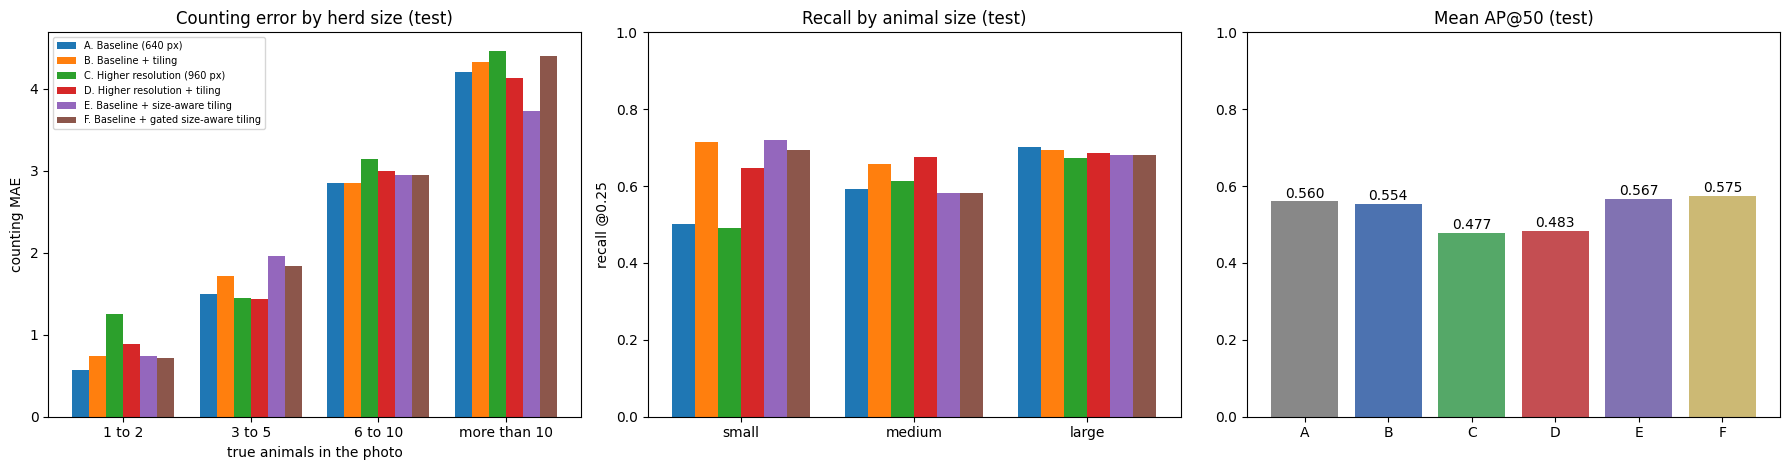

In [18]:
names = list(VARIANTS)
short = [n.split(".")[0] for n in names]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
w = 0.8 / len(names); mid = (len(names) - 1) / 2 * w
for i, v in enumerate(names):
    g = herd[herd.Variant == v].set_index("herd").reindex(HERD_LABELS)
    ax[0].bar(np.arange(len(HERD_LABELS)) + i * w, g.MAE, w, label=v)
ax[0].set_xticks(np.arange(len(HERD_LABELS)) + mid); ax[0].set_xticklabels(HERD_LABELS)
ax[0].set_xlabel("true animals in the photo"); ax[0].set_ylabel("counting MAE"); ax[0].set_title("Counting error by herd size (test)"); ax[0].legend(fontsize=7)

m2 = main.set_index("Variant")
for i, v in enumerate(names):
    ax[1].bar(np.arange(3) + i * w, [m2.loc[v, "Recall small"], m2.loc[v, "Recall medium"], m2.loc[v, "Recall large"]], w, label=v)
ax[1].set_xticks(np.arange(3) + mid); ax[1].set_xticklabels(["small", "medium", "large"]); ax[1].set_ylim(0, 1)
ax[1].set_ylabel("recall @0.25"); ax[1].set_title("Recall by animal size (test)")

ax[2].bar(short, m2["AP50 mean"], color=["#888", "#4c72b0", "#55a868", "#c44e52", "#8172b2", "#ccb974"][:len(names)]); ax[2].set_ylim(0, 1)
for i, v in enumerate(m2["AP50 mean"]):
    ax[2].text(i, v + 0.01, f"{v:.3f}", ha="center")
ax[2].set_title("Mean AP@50 (test)")
savefig("fig_D3_comparison.png")

In [19]:
def op_row(v):
    thr = thr_best[v]
    tp, fp, fn, recs = match_dets(P[(v, "test")], GT["test"], thr)
    recs["size"] = pd.cut(recs.area, SIZE_BINS, labels=SIZE_LABELS)
    rs = recs.groupby("size", observed=True).hit.mean()
    return {"Variant": v, "Threshold": thr, "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1),
            "Recall small": float(rs.get(SIZE_LABELS[0], np.nan)), "Recall medium": float(rs.get(SIZE_LABELS[1], np.nan)),
            "Recall large": float(rs.get(SIZE_LABELS[2], np.nan))}

op = pd.DataFrame([op_row(v) for v in VARIANTS]); op.to_csv(TAB_DIR / "d3_operating_point_test.csv", index=False)
display(op.set_index("Variant").round(3))
sizes = pd.cut(np.concatenate([g[2] for g in GT["test"].values()]), SIZE_BINS, labels=SIZE_LABELS).value_counts().reindex(SIZE_LABELS)
print("Ground-truth boxes per size group (test):", sizes.to_dict())

,Threshold,Precision,Recall,Recall small,Recall medium,Recall large
Variant,,,,,,
A. Baseline (640 px),0.30,0.616,0.577,0.478,0.578,0.694
B. Baseline + tiling,0.50,0.616,0.600,0.624,0.568,0.609
C. Higher resolution (960 px),0.25,0.539,0.588,0.492,0.613,0.673
D. Higher resolution + tiling,0.50,0.625,0.555,0.569,0.575,0.516
E. Baseline + size-aware tiling,0.40,0.592,0.611,0.661,0.523,0.653
F. Baseline + gated size-aware tiling,0.35,0.588,0.618,0.658,0.537,0.665


Ground-truth boxes per size group (test): {'small (<1%)': 295, 'medium (1-10%)': 287, 'large (>10%)': 248}


In [20]:
ap_cols = ["AP50 Cattle", "AP50 Goat", "AP50 Sheep", "AP50 mean"]
m2 = main.set_index("Variant")[ap_cols]
delta = m2.sub(m2.loc[BASE], axis=1).drop(index=BASE)
display(delta.round(3))
delta.to_csv(TAB_DIR / "d3_ap_change_vs_baseline.csv")

,AP50 Cattle,AP50 Goat,AP50 Sheep,AP50 mean
Variant,,,,
B. Baseline + tiling,0.051,0.010,-0.081,-0.007
C. Higher resolution (960 px),-0.008,-0.124,-0.116,-0.083
D. Higher resolution + tiling,0.014,-0.145,-0.101,-0.077
E. Baseline + size-aware tiling,0.045,0.024,-0.048,0.007
F. Baseline + gated size-aware tiling,0.049,0.028,-0.032,0.015


In [21]:
def per_image(v):
    return count_df(P[(v, "test")], GT["test"], thr_best[v]).set_index("image")

def paired_boot(a, b, n, seed):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(a), size=(n, len(a)))
    d = (b[idx] - a[idx]).mean(axis=1)
    return float((b - a).mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

base_img = per_image(BASE)
big = (base_img.gt_total > 5).values
BOOT, rows = {}, []
for v in VARIANTS:
    if v == BASE:
        continue
    dv = per_image(v).loc[base_img.index]
    allp = paired_boot(base_img.abs_error.values, dv.abs_error.values, N_BOOT_MAE, SEED)
    bigp = paired_boot(base_img.abs_error.values[big], dv.abs_error.values[big], N_BOOT_MAE, SEED)
    BOOT[v] = dict(all=allp, big=bigp)
    rows.append({"Variant": v, "MAE change (all)": allp[0], "low": allp[1], "high": allp[2],
                 "MAE change (>5 animals)": bigp[0], "low (>5)": bigp[1], "high (>5)": bigp[2]})
boot_tab = pd.DataFrame(rows); boot_tab.to_csv(TAB_DIR / "d3_bootstrap_counting.csv", index=False)
display(boot_tab.set_index("Variant").round(3))
print("Photos with more than 5 animals (test):", int(big.sum()), "of", len(big))

,MAE change (all),low,high,MAE change (>5 animals),low (>5),high (>5)
Variant,,,,,,
B. Baseline + tiling,0.164,-0.058,0.382,0.056,-1.000,0.944
C. Higher resolution (960 px),0.418,0.213,0.649,0.278,-0.389,0.944
D. Higher resolution + tiling,0.173,-0.022,0.356,0.056,-0.612,0.694
E. Baseline + size-aware tiling,0.200,-0.085,0.489,-0.139,-1.529,0.945
F. Baseline + gated size-aware tiling,0.191,-0.067,0.431,0.139,-1.278,1.306


Photos with more than 5 animals (test): 36 of 225


In [22]:
def boot_ap_diff(v_a, v_b, n, seed):
    rng = np.random.default_rng(seed)
    names = list(GT["test"])
    diffs = []
    for _ in range(n):
        pick = rng.integers(0, len(names), len(names))
        keys = [f"{names[i]}#{j}" for j, i in enumerate(pick)]
        g = {k: GT["test"][names[i]] for k, i in zip(keys, pick)}
        pa = {k: P[(v_a, "test")][names[i]] for k, i in zip(keys, pick)}
        pb = {k: P[(v_b, "test")][names[i]] for k, i in zip(keys, pick)}
        diffs.append(np.mean(ap50_per_class(pb, g)) - np.mean(ap50_per_class(pa, g)))
    point = float(np.mean(ap50_per_class(P[(v_b, "test")], GT["test"])) - np.mean(ap50_per_class(P[(v_a, "test")], GT["test"])))
    return point, float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))

BOOT_AP = boot_ap_diff(BASE, SELECTED, N_BOOT_AP, SEED)
print(f"mAP@50 change, {SELECTED} minus baseline: {BOOT_AP[0]:+.3f}  (95% interval {BOOT_AP[1]:+.3f} to {BOOT_AP[2]:+.3f})")

mAP@50 change, F. Baseline + gated size-aware tiling minus baseline: +0.015  (95% interval -0.023 to +0.050)


In [23]:
def time_variant(var, n, device, fresh_model=False):
    files = list_images(DATA_DIR / "images" / "test")[:n]
    imgs = [cv2.imread(str(f)) for f in files]
    model = YOLO(str(var["weights"])) if fresh_model else var["model"]
    cfg = dict(imgsz=var["imgsz"], conf=CONF_REF, iou=IOU_NMS, device=device,
               tile=(var["tiling"] or {}).get("tile"), overlap=TILE_OVERLAP, merge_iou=(var["tiling"] or {}).get("merge_iou", 0.55),
               tile_max_area=(var["tiling"] or {}).get("max_area"),
               gate_k=(var["tiling"] or {}).get("gate_k"), gate_conf=(var["tiling"] or {}).get("gate_conf", 0.3))
    for im in imgs[:2]:
        run_pipeline(model, im, cfg)
    if device != "cpu" and torch.cuda.is_available():
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    ts = []
    for im in imgs:
        t = time.perf_counter(); run_pipeline(model, im, cfg)
        if device != "cpu" and torch.cuda.is_available():
            torch.cuda.synchronize()
        ts.append((time.perf_counter() - t) * 1000)
    mem = torch.cuda.max_memory_allocated() / 1e6 if (device != "cpu" and torch.cuda.is_available()) else float("nan")
    return float(np.mean(ts)), mem

speed_rows = []
for v, var in VARIANTS.items():
    g_ms, g_mem = time_variant(var, 40, DEVICE)
    c_ms, _ = time_variant(var, 8, "cpu", fresh_model=True)
    speed_rows.append({"Variant": v, "GPU ms/image": g_ms, "GPU images/s": 1000 / g_ms, "Peak GPU memory (MB)": g_mem,
                       "CPU ms/image": c_ms, "CPU images/s": 1000 / c_ms,
                       "Weights (MB)": Path(var["weights"]).stat().st_size / 1e6})
speed = pd.DataFrame(speed_rows); speed.to_csv(TAB_DIR / "d3_speed_and_memory.csv", index=False)
display(speed.round(2))

,Variant,GPU ms/image,GPU images/s,Peak GPU memory (MB),CPU ms/image,CPU images/s,Weights (MB)
0,A. Baseline (640 px),12.46,80.28,47.29,69.61,14.37,6.48
1,B. Baseline + tiling,91.22,10.96,457.78,1025.13,0.98,6.48
2,C. Higher resolution (960 px),17.48,57.22,73.29,123.84,8.07,6.52
3,D. Higher resolution + tiling,121.02,8.26,716.86,1256.85,0.80,6.52
4,E. Baseline + size-aware tiling,92.41,10.82,457.77,958.80,1.04,6.48
5,F. Baseline + gated size-aware tiling,51.28,19.50,386.90,565.74,1.77,6.48


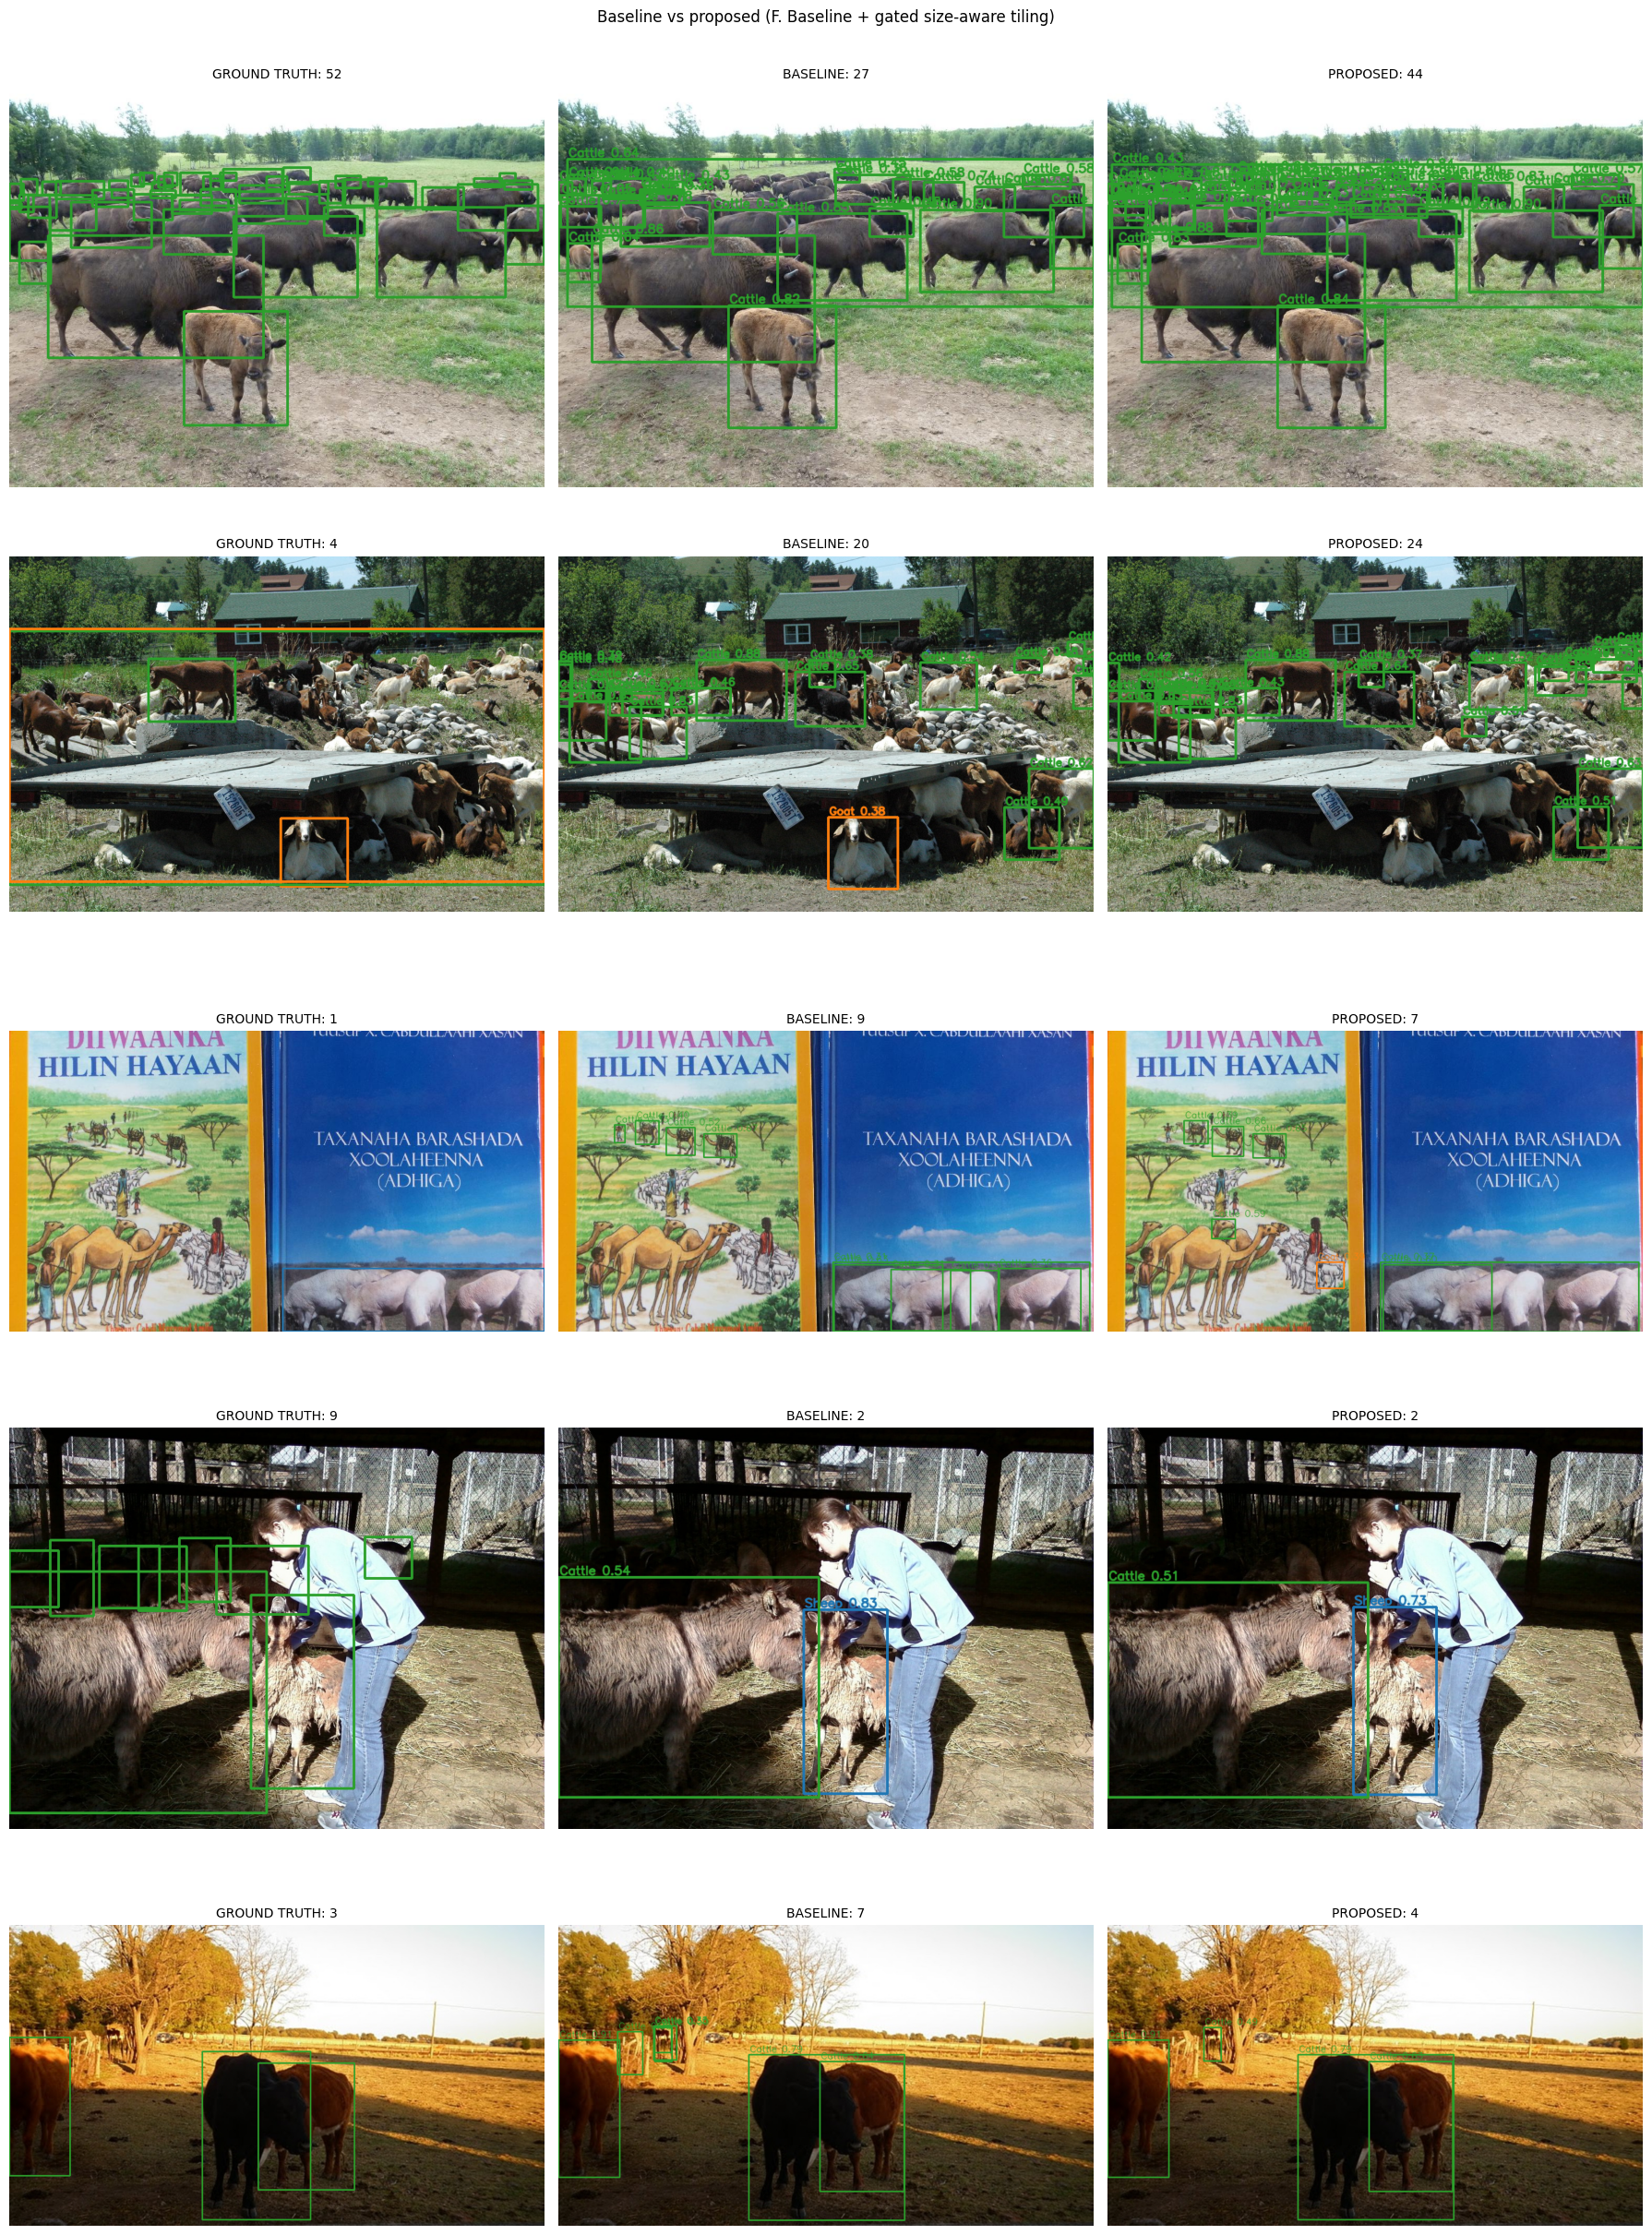

Images where the proposed system is worse than the baseline: 42 of 225


,gt,baseline,proposed
image,,,
51befc9af2100a51.jpg,19,18,31
646e60b7163f4d9c.jpg,5,4,16
1c07289777a4e092.jpg,1,4,11
e64dc13a14840b2e.jpg,10,11,17
dcd58dbfeef7b6e8.jpg,2,8,14


In [24]:
def draw_preds(img_bgr, pred, thr):
    h, w = img_bgr.shape[:2]
    out, t = img_bgr.copy(), max(2, int(round(min(h, w) / 250)))
    for (x1, y1, x2, y2), c, cf in zip(pred["xyxyn"], pred["cls"], pred["conf"]):
        if cf < thr:
            continue
        p1, p2 = (int(x1 * w), int(y1 * h)), (int(x2 * w), int(y2 * h))
        cv2.rectangle(out, p1, p2, BOX_BGR[int(c)], t)
        cv2.putText(out, f"{CLASSES[int(c)]} {cf:.2f}", (p1[0] + 2, max(p1[1] - 5, 14)), cv2.FONT_HERSHEY_SIMPLEX,
                    max(0.5, min(h, w) / 1000), BOX_BGR[int(c)], max(1, t - 1), cv2.LINE_AA)
    return out

def draw_gt(img_bgr, name):
    gc, gb, _ = GT["test"][name]
    h, w = img_bgr.shape[:2]
    out, t = img_bgr.copy(), max(2, int(round(min(h, w) / 250)))
    for c, (x1, y1, x2, y2) in zip(gc, gb):
        cv2.rectangle(out, (int(x1 * w), int(y1 * h)), (int(x2 * w), int(y2 * h)), BOX_BGR[int(c)], t)
    return out

dB = count_df(P[(BASE, "test")], GT["test"], thr_best[BASE]).set_index("image")
dS = count_df(P[(SELECTED, "test")], GT["test"], thr_best[SELECTED]).set_index("image")
worst = dB.sort_values("abs_error", ascending=False).head(4).index.tolist()
easy = (dB.abs_error - dS.abs_error).sort_values(ascending=False).head(2).index.tolist()     # biggest improvements
show = list(dict.fromkeys(worst + easy))[:6]
fig, axes = plt.subplots(len(show), 3, figsize=(18, 5 * len(show)))
for row, n in zip(axes, show):
    img = cv2.imread(str(DATA_DIR / "images" / "test" / n))
    row[0].imshow(rgb(draw_gt(img, n))); row[0].set_title(f"GROUND TRUTH: {int(dB.loc[n, 'gt_total'])}", fontsize=10)
    row[1].imshow(rgb(draw_preds(img, P[(BASE, 'test')][n], thr_best[BASE]))); row[1].set_title(f"BASELINE: {int(dB.loc[n, 'pred_total'])}", fontsize=10)
    row[2].imshow(rgb(draw_preds(img, P[(SELECTED, 'test')][n], thr_best[SELECTED]))); row[2].set_title(f"PROPOSED: {int(dS.loc[n, 'pred_total'])}", fontsize=10)
    for a in row: a.axis("off")
plt.suptitle(f"Baseline vs proposed ({SELECTED})", y=1.0)
savefig("fig_D3_side_by_side.png")

# worse cases: images where the proposed system is further from the truth than the baseline
hurt = (dS.abs_error - dB.abs_error).sort_values(ascending=False)
print("Images where the proposed system is worse than the baseline:", int((hurt > 0).sum()), "of", len(hurt))
display(pd.DataFrame({"gt": dB.gt_total, "baseline": dB.pred_total, "proposed": dS.pred_total}).loc[hurt.head(5).index])
for n in worst[:3] + easy[:2]:      # also save annotated outputs for the report
    img = cv2.imread(str(DATA_DIR / "images" / "test" / n))
    cv2.imwrite(str(PRED_DIR / f"proposed_{n}"), draw_preds(img, P[(SELECTED, 'test')][n], thr_best[SELECTED]))

In [25]:
xrows = []
for v in (NAME_A, NAME_C):
    var = VARIANTS[v]
    vm = var["model"].val(data=str(DATA_YAML), split="test", imgsz=var["imgsz"], batch=BATCH_BASE, conf=0.001, iou=0.6, plots=False,
                          project=str(RUNS_DIR), name="xcheck_" + v[0], exist_ok=True, device=DEVICE, verbose=False)
    xrows.append({"Variant": v, "Ultralytics P": vm.box.mp, "Ultralytics R": vm.box.mr, "mAP@50": vm.box.map50, "mAP@50-95": vm.box.map})
xc = pd.DataFrame(xrows); xc.to_csv(TAB_DIR / "d3_ultralytics_crosscheck.csv", index=False); display(xc.round(3))

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3012.7±532.9 MB/s, size: 390.7 KB)
val: Scanning /kaggle/working/livestock_dataset/labels/test... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 1.2Kit/s 0.2s
val: New cache created: /kaggle/working/livestock_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 6.5it/s 2.3s
                   all        225        830      0.611      0.566      0.586      0.354
Speed: 0.7ms preprocess, 4.2ms inference, 0.0ms loss, 1.1ms postprocess per image
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3620.1±864.7 MB/s, siz

,Variant,Ultralytics P,Ultralytics R,mAP@50,mAP@50-95
0,A. Baseline (640 px),0.611,0.566,0.586,0.354
1,C. Higher resolution (960 px),0.586,0.492,0.511,0.302


### Own metric code against the official validator
The tiled variants can only be scored with the notebook's own AP code. The gap between the two on the whole-photo variants gives an idea of how far the own code can be trusted.

In [26]:
cmp_ap = xc.set_index("Variant")[["mAP@50"]].rename(columns={"mAP@50": "Ultralytics mAP@50"}).join(main.set_index("Variant")[["AP50 mean"]].rename(columns={"AP50 mean": "Own AP50"}))
cmp_ap["Own minus official"] = cmp_ap["Own AP50"] - cmp_ap["Ultralytics mAP@50"]
cmp_ap.to_csv(TAB_DIR / "d3_own_vs_official_ap.csv")
display(cmp_ap.round(3))

,Ultralytics mAP@50,Own AP50,Own minus official
Variant,,,
A. Baseline (640 px),0.586,0.560,-0.026
C. Higher resolution (960 px),0.511,0.477,-0.033


In [27]:
def interval_word(lo, hi, lower_is_better=True):
    if lo > 0:
        return "worse" if lower_is_better else "better"
    if hi < 0:
        return "better" if lower_is_better else "worse"
    return "not clearly different from the baseline"

mm, oo = main.set_index("Variant"), op.set_index("Variant")
hp = herd.pivot(index="herd", columns="Variant", values="MAE").reindex(HERD_LABELS)
sp = speed.set_index("Variant")
ba, se = BASE, SELECTED
a_all, a_big = BOOT[se]["all"], BOOT[se]["big"]

lines = [
    f"Best improved variant on validation: {se}. Configuration deployed: {DEPLOY}.",
    f"Small-animal recall at the chosen thresholds: {oo.loc[ba, 'Recall small']:.2f} for the baseline and {oo.loc[se, 'Recall small']:.2f} for {se}; "
    f"precision changes from {oo.loc[ba, 'Precision']:.2f} to {oo.loc[se, 'Precision']:.2f}.",
    f"Overall counting MAE: {mm.loc[ba, 'MAE@chosen']:.2f} to {mm.loc[se, 'MAE@chosen']:.2f} "
    f"(change {a_all[0]:+.2f}, 95% interval {a_all[1]:+.2f} to {a_all[2]:+.2f}): {interval_word(a_all[1], a_all[2])}.",
    f"MAE on photos with more than 5 animals: {mm.loc[ba, 'MAE (>5 animals)@chosen']:.2f} to {mm.loc[se, 'MAE (>5 animals)@chosen']:.2f} "
    f"(change {a_big[0]:+.2f}, interval {a_big[1]:+.2f} to {a_big[2]:+.2f}): {interval_word(a_big[1], a_big[2])}.",
    f"Mean AP@50 change {BOOT_AP[0]:+.3f} (interval {BOOT_AP[1]:+.3f} to {BOOT_AP[2]:+.3f}): {interval_word(BOOT_AP[1], BOOT_AP[2], lower_is_better=False)}.",
]
better = [h for h in HERD_LABELS if hp.loc[h, se] < hp.loc[h, ba]]
worse = [h for h in HERD_LABELS if hp.loc[h, se] > hp.loc[h, ba]]
lines.append(f"Counting MAE by herd size is lower than the baseline for: {', '.join(better) or 'no group'}; higher for: {', '.join(worse) or 'no group'}.")
cls_worse = [c for c in ["Cattle", "Goat", "Sheep"] if mm.loc[se, f"AP50 {c}"] < mm.loc[ba, f"AP50 {c}"]]
lines.append(f"Classes with a lower AP@50 than the baseline: {', '.join(cls_worse) or 'none'}.")
lines.append(f"Higher resolution alone (variant C) gives mean AP@50 {mm.loc[NAME_C, 'AP50 mean']:.3f} against {mm.loc[ba, 'AP50 mean']:.3f} for the baseline.")
lines.append(f"Cost: {sp.loc[se, 'CPU ms/image'] / sp.loc[ba, 'CPU ms/image']:.1f} times the CPU time and {sp.loc[se, 'GPU ms/image'] / sp.loc[ba, 'GPU ms/image']:.1f} times the GPU time per image of the baseline.")
CONCLUSION = "\n".join("- " + l for l in lines)
(OUT_DIR / "conclusion_d3.txt").write_text(CONCLUSION + "\n")
print(CONCLUSION)

- Best improved variant on validation: F. Baseline + gated size-aware tiling. Configuration deployed: F. Baseline + gated size-aware tiling.
- Small-animal recall at the chosen thresholds: 0.48 for the baseline and 0.66 for F. Baseline + gated size-aware tiling; precision changes from 0.62 to 0.59.
- Overall counting MAE: 1.28 to 1.47 (change +0.19, 95% interval -0.07 to +0.43): not clearly different from the baseline.
- MAE on photos with more than 5 animals: 3.42 to 3.56 (change +0.14, interval -1.28 to +1.31): not clearly different from the baseline.
- Mean AP@50 change +0.015 (interval -0.023 to +0.050): not clearly different from the baseline.
- Counting MAE by herd size is lower than the baseline for: no group; higher for: 1 to 2, 3 to 5, 6 to 10, more than 10.
- Classes with a lower AP@50 than the baseline: Sheep.
- Higher resolution alone (variant C) gives mean AP@50 0.477 against 0.560 for the baseline.
- Cost: 8.1 times the CPU time and 4.1 times the GPU time per image of the

In [28]:
sel = VARIANTS[DEPLOY]
(OUT_DIR / "weights").mkdir(exist_ok=True)
shutil.copy2(BASE_BEST, OUT_DIR / "weights" / "baseline_best.pt")
shutil.copy2(sel["weights"], OUT_DIR / "weights" / "proposed_best.pt")
sel_t = sel["tiling"] or {}
config_d3 = dict(selected_variant=DEPLOY, weights="weights/proposed_best.pt", classes=CLASSES, imgsz=sel["imgsz"],
                 conf=float(thr_best[DEPLOY]), iou=IOU_NMS,
                 tile=sel_t.get("tile"), overlap=TILE_OVERLAP, merge_iou=sel_t.get("merge_iou"),
                 tile_max_area=sel_t.get("max_area"), gate_k=sel_t.get("gate_k"), gate_conf=sel_t.get("gate_conf"))
(OUT_DIR / "config_d3.json").write_text(json.dumps(config_d3, indent=2))
print(json.dumps(config_d3, indent=2))

{
  "selected_variant": "F. Baseline + gated size-aware tiling",
  "weights": "weights/proposed_best.pt",
  "classes": [
    "Cattle",
    "Goat",
    "Sheep"
  ],
  "imgsz": 640,
  "conf": 0.35,
  "iou": 0.7,
  "tile": 384,
  "overlap": 0.25,
  "merge_iou": 0.6,
  "tile_max_area": 0.01,
  "gate_k": 3,
  "gate_conf": 0.3
}


In [29]:
try:
    export_dir = WORK / "onnx_export"; export_dir.mkdir(exist_ok=True)
    tmp_pt = export_dir / "proposed_best.pt"; shutil.copy2(sel["weights"], tmp_pt)
    onnx_path = YOLO(str(tmp_pt)).export(format="onnx", imgsz=sel["imgsz"])
    shutil.copy2(onnx_path, OUT_DIR / "weights" / "proposed_best.onnx")
    print("ONNX exported:", onnx_path)
except Exception as e:
    print("ONNX export skipped:", e)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/kaggle/working/onnx_export/proposed_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 430ms
 Downloaded onnxruntime
Prepared 2 packages in 368ms
Installed 2 packages in 11ms
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export s

In [30]:
tr = OUT_DIR / "training_results_960"; tr.mkdir(exist_ok=True)
for f in list((BEST_HI.parent.parent).glob("*.png")) + list((BEST_HI.parent.parent).glob("*.csv")):
    shutil.copy2(f, tr / f.name)
(OUT_DIR / "splits").mkdir(exist_ok=True)
for s in split_names:
    (OUT_DIR / "splits" / f"{s}.txt").write_text("\n".join(split_names[s]) + "\n")

In [31]:
env = {"date": datetime.datetime.now().isoformat(timespec="seconds"), "python": platform.python_version(), "platform": platform.platform(),
       "torch": torch.__version__, "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)",
       "ultralytics": ultralytics.__version__, "numpy": np.__version__, "pandas": pd.__version__, "opencv": cv2.__version__}
provenance = dict(splits_dir=str(SPLITS_DIR), baseline_weights=str(BASE_BEST), weights_960=str(BEST_HI),
                  weights_960_reused=PREV_960 is not None, dataset_source=DATASET_SOURCE)
settings = dict(SEED=SEED, EPOCHS=EPOCHS, PATIENCE=PATIENCE, BATCH_BASE=BATCH_BASE, BATCH_HI=BATCH_HI, IMGSZ_BASE=IMGSZ_BASE, IMGSZ_HI=IMGSZ_HI,
                IOU_NMS=IOU_NMS, CONF_REF=CONF_REF, TILE_GRID=TILE_GRID, MERGE_IOU_GRID=MERGE_IOU_GRID, TILE_OVERLAP=TILE_OVERLAP,
                GATE_K_GRID=GATE_K_GRID, GATE_CONF=GATE_CONF, N_BOOT_MAE=N_BOOT_MAE, N_BOOT_AP=N_BOOT_AP,
                tiling_B=tilingB, tiling_D=tilingD, tiling_E=tilingE, tiling_F=tilingF, train_minutes_960=train_minutes, provenance=provenance)
(OUT_DIR / "env.json").write_text(json.dumps(env, indent=2)); (OUT_DIR / "settings_d3.json").write_text(json.dumps(settings, indent=2, default=str))
(OUT_DIR / "requirements.txt").write_text(f"ultralytics=={env['ultralytics']}\ntorch=={env['torch']}\nnumpy=={env['numpy']}\npandas=={env['pandas']}\nopencv-python=={env['opencv']}\nmatplotlib\ngradio  # for the PC app\n")
print(json.dumps(provenance, indent=2))

{
  "splits_dir": "/kaggle/input/notebooks/amanyaedwin/deliverable-3/outputs/splits",
  "baseline_weights": "/kaggle/input/notebooks/amanyaedwin/deliverable-2/outputs/weights/best.pt",
  "weights_960": "/kaggle/input/notebooks/amanyaedwin/deliverable-3/runs/d3_yolov8n_960/weights/best.pt",
  "weights_960_reused": true,
  "dataset_source": "attached dataset /kaggle/input/notebooks/amanyaedwin/deliverable-3/livestock_dataset"
}


In [32]:
def md_table(df, fmt="{:.3f}"):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(fmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in r) + " |")
    return "\n".join(lines)

t_main = md_table(main[["Variant", "AP50 mean", "Recall small", "MAE@0.25", "MAE@chosen", "MAE (>5 animals)@chosen", "Bias@chosen"]])
t_op = md_table(op)
t_boot = md_table(boot_tab)
t_crit = md_table(crit)
t_speed = md_table(speed, "{:.2f}")
readme = f'''# Livestock Detection and Counting: Deliverable 3 (same dataset as D2)

Deployed configuration: **{DEPLOY}** (counting threshold {thr_best[DEPLOY]}).
Best improved variant on validation: **{SELECTED}**.
Settings are in `config_d3.json`; inference code is in `pipeline.py`. The ONNX file holds the detector only; tiling runs through `pipeline.py`.

## Conclusions
{CONCLUSION}

## Results on the held-out test photos
{t_main}

## Precision and recall at the validation-chosen thresholds
{t_op}

## Change in counting MAE against the baseline (95% bootstrap interval)
{t_boot}

## Hypothesis check
{t_crit}

## Speed and memory
{t_speed}

## Use the deployed model in Python
```python
import json, cv2
from ultralytics import YOLO
from pipeline import run_pipeline
cfg = json.load(open("config_d3.json"))
model = YOLO(cfg["weights"])
pred, counts = run_pipeline(model, cv2.imread("farm.jpg"), cfg)
print(counts)
```
'''
(OUT_DIR / "README_D3.md").write_text(readme)

4659

In [33]:
def zip_folder(folder, zip_path):
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for f in sorted(Path(folder).rglob("*")):
            if f.is_file():
                z.write(f, f.relative_to(folder))
    return zip_path
pkg = zip_folder(OUT_DIR, WORK / "deliverable3_package.zip")
print(f"Package: {pkg} ({pkg.stat().st_size / 1e6:.1f} MB)")
print("On Kaggle: Save Version > Save & Run All (Commit), then Output tab > download deliverable3_package.zip")

Package: /kaggle/working/deliverable3_package.zip (30.8 MB)
On Kaggle: Save Version > Save & Run All (Commit), then Output tab > download deliverable3_package.zip
